# Homework 2


In [50]:
import numpy as np
from scipy.optimize import minimize
from collections.abc import Callable
import matplotlib.pyplot as plt

# European call payoff

In [51]:
def european_call_payoff(S: float, K: float) -> float:
    return max(S - K, 0.0)

## Create Spot Tree

In [52]:
def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

## Create Price Tree

In [53]:
def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        # init delta tree
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]] #delta makes no sense for leaves
    # going backwards, payoff is known in leaves
    for i in range(len(spot_tree[-1])):
        spot = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

## Balanced Tree

In [54]:
def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

In [55]:
def calculate_call_price(spot: float, strike: float, discount_factor: float, steps: int, spot_mult_up: float) -> float:
    spot_mult_down = calcBalancedDownStep(spot_mult_up, discount_factor)
    spot_tree = create_spot_tree(spot, spot_mult_up, spot_mult_down, steps)
    price_tree = create_discounted_price_tree(spot_tree, discount_factor, strike)
    return price_tree[0][0]

# Assignment
## Implement calibrator for Tree

* Background: In the Black--Scholes model volatility is a key parameter that determines option price. In a Balanced Binomial Tree (i.e. risk-neutral up step probability $= 0.5$ risk-neutral down step probability $= 0.5$) the same role is played by step size: higher step is like higher volatility, it results in higher option prices. Also, there is a 1-1 correspondence between step size and price if all other parameters are fixed.
* Task: Write a calibrate method which, for a given number of steps parameter, computes the up step size for which a Balanced Binomial Tree model returns the specified price for a given European call. (In practice option prices can be observed in the market, so it makes sense to assume it is given). Demonstrate the calibrate method for various input parameters (same contract with a few different number of steps (dont forget to scale the discount factor to keep interest rates flat); calibrate one step tree for various contracts (different expiries and strike levels, flat interest rate)). Make simple plots to illustrate results.
* Hint: To do it you will need to use a root solver, I recommend using scipy.optimize.minimize.

Q#1 Write a calibrate method which, for a given number of steps parameter, computes the up step size for which a Balanced Binomial Tree model returns the specified price for a given European call. (In practice option prices can be observed in the market, so it makes sense to assume it is given)

# Solution

Let us calibrate the balanced binomial tree for different numbers of steps while keeping the annual interest rate fixed at 5%. The discount factor per step is $e^{-rT/N}$, where $r$ is the annual interest rate, $T$ is the maturity, and $N$ is the number of steps.

In [57]:
def calibrate(spot: float,strike: float,discount_factor: float,steps: int,market_price: float) -> float:
    def objective(x):
        up_step = x[0]
        model_price = calculate_call_price(spot,strike,discount_factor,steps,up_step)
        return (model_price - market_price) ** 2
    lower = 1.0 / discount_factor + 1e-6
    upper = 2.0 / discount_factor - 1e-6          
    result = minimize(objective, x0=[1.3], bounds=[(lower, upper)], method="Nelder-Mead", options={"xatol": 1e-10, "fatol": 1e-14,"maxiter": 5000})
    if not result.success: 
        raise ValueError("Optimizer did not converge.")
    calibrated_up = result.x[0]
    model_price = calculate_call_price(spot, strike, discount_factor, steps, calibrated_up)
    if abs(model_price - market_price) > 1e-6:
        raise ValueError("Calibration did not reproduce the target price.")
    return calibrated_up

The function minimizes the squared difference between the model price and the target market price. It returns the calibrated up-step multiplier when the resulting model price matches the target within the specified tolerance.

Q#2 Demonstrate the calibrate method for various input parameters (same contract with a few different number of steps (dont forget to scale the discount factor to keep interest rates flat).

# Solution

In [ ]:
spot = 1.0
strike = 1.0
maturity = 1.0
interest_rate = 0.05
reference_steps = 5
reference_discount_factor = np.exp(-interest_rate * maturity / reference_steps)
market_price = calculate_call_price(spot=spot,strike=strike, discount_factor=reference_discount_factor,steps=reference_steps,spot_mult_up=1.2)
print("Target market price:", market_price)
step_counts = [1, 2, 5, 10, 20, 50]
results = []
for steps in step_counts:
    discount_factor = np.exp(-interest_rate * maturity / steps)
    calibrated_up = calibrate(spot=spot,strike=strike,discount_factor=discount_factor,steps=steps,market_price=market_price)
    calibrated_down = calcBalancedDownStep(calibrated_up,discount_factor)
    model_price = calculate_call_price(spot=spot,strike=strike,discount_factor=discount_factor,steps=steps,spot_mult_up=calibrated_up)
    results.append((steps, discount_factor, calibrated_up,calibrated_down, model_price))

for row in results:
    print(
        f"N={row[0]:2d}, "
        f"discount factor={row[1]:.6f}, "
        f"up={row[2]:.6f}, "
        f"down={row[3]:.6f}, "
        f"model price={row[4]:.6f}"
    )


Target market price: 0.1965785707973573
N= 1, discount factor=0.951229, up=1.413315, down=0.689227, model price=0.196579
N= 2, discount factor=0.975310, up=1.351529, down=0.699102, model price=0.196579
N= 5, discount factor=0.990050, up=1.200000, down=0.820100, model price=0.196579
N=10, discount factor=0.995012, up=1.144750, down=0.865275, model price=0.196579
N=20, discount factor=0.997503, up=1.101073, down=0.903933, model price=0.196579
N=50, discount factor=0.999000, up=1.063418, down=0.938583, model price=0.196579


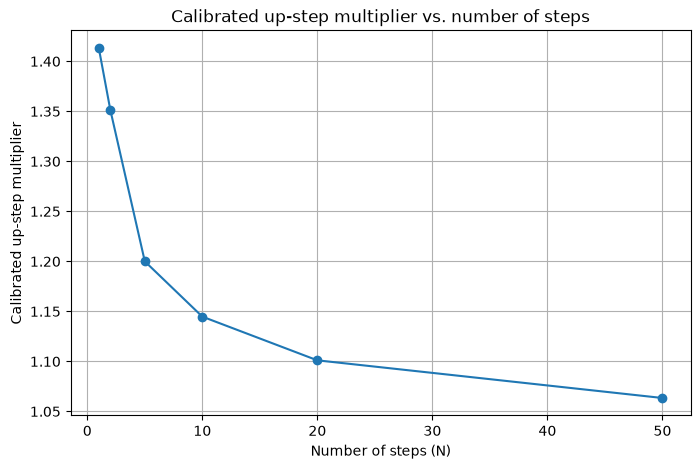

In [59]:
step_counts_done = [row[0] for row in results]
up_steps_done = [row[2] for row in results]

plt.figure(figsize=(8, 5))
plt.plot(step_counts_done, up_steps_done, marker="o")
plt.xlabel("Number of steps (N)")
plt.ylabel("Calibrated up-step multiplier")
plt.title("Calibrated up-step multiplier vs. number of steps")
plt.grid(True)
plt.show()

The results show how the calibrated up-step multiplier changes with the number of steps while reproducing the target option price.

Q#3 Calibrate one step tree for various contracts (different expiries and strike levels, flat interest rate)). Make simple plots to illustrate results.

# Solution

To test the calibrator for different contracts, I generate target prices using a one-step tree with an up-step multiplier of 1.3. I then calibrate the tree using these prices.

In [ ]:
spot = 1.0
interest_rate = 0.05
steps = 1
maturities = [0.5, 1.0, 2.0]
strikes = [0.8, 1.0, 1.2]
results_one_step = []
for maturity in maturities:
    discount_factor = np.exp(-interest_rate * maturity)
    for strike in strikes:
        market_price = calculate_call_price(spot, strike, discount_factor, steps, 1.3)
        calibrated_up = calibrate(spot, strike, discount_factor, steps, market_price)
        results_one_step.append((maturity, strike, market_price, calibrated_up))
for row in results_one_step:
    print(
        f"Maturity={row[0]:.1f}, "
        f"Strike={row[1]:.1f}, "
        f"Price={row[2]:.4f}, "
        f"Calibrated up={row[3]:.4f}"
    )

Maturity=0.5, Strike=0.8, Price=0.2438, Calibrated up=1.3000
Maturity=0.5, Strike=1.0, Price=0.1463, Calibrated up=1.3000
Maturity=0.5, Strike=1.2, Price=0.0488, Calibrated up=1.3000
Maturity=1.0, Strike=0.8, Price=0.2390, Calibrated up=1.3000
Maturity=1.0, Strike=1.0, Price=0.1427, Calibrated up=1.3000
Maturity=1.0, Strike=1.2, Price=0.0476, Calibrated up=1.3000
Maturity=2.0, Strike=0.8, Price=0.2761, Calibrated up=1.3000
Maturity=2.0, Strike=1.0, Price=0.1357, Calibrated up=1.3000
Maturity=2.0, Strike=1.2, Price=0.0452, Calibrated up=1.3000


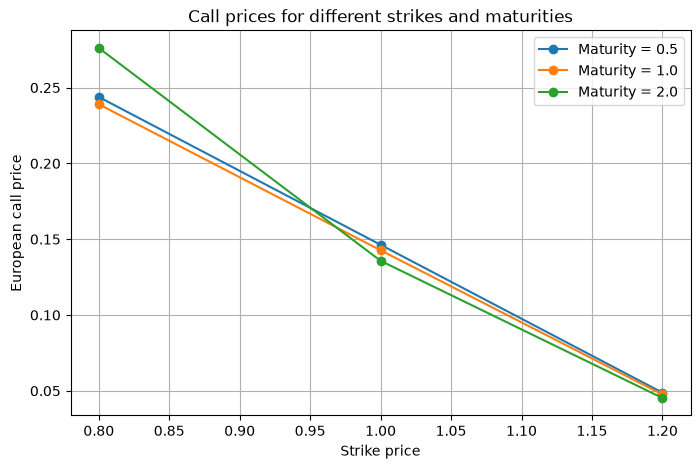

In [61]:
plt.figure(figsize=(8, 5))
for maturity in maturities:
    selected = [row for row in results_one_step if row[0] == maturity]
    plt.plot( [row[1] for row in selected], [row[2] for row in selected], marker="o", label=f"Maturity = {maturity}")

plt.xlabel("Strike price")
plt.ylabel("European call price")
plt.title("Call prices for different strikes and maturities")
plt.legend()
plt.grid(True)
plt.show()

I plotted the calibrated up-step multiplier against the number of steps and plotted the call prices for different strikes and maturities.